Lab - EDA Univariate Analysis: Diving into Amazon UK Product Insights
Objective: Explore the product listing dynamics on Amazon UK to extract actionable business insights. By understanding the distribution, central tendencies, and relationships of various product attributes, businesses can make more informed decisions on product positioning, pricing strategies, and inventory management.

Dataset: This lab utilizes the Amazon UK product dataset which provides information on product categories, brands, prices, ratings, and more from from Amazon UK. You'll need to download it to start working with it.



In [32]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
df = pd.read_csv("amz_uk_price_prediction_dataset.csv")

- Identify the dimensions of the dataset (number of rows and columns)
- Identitfy the type
- Identify duplicate for asin (Product ID from Amazon) because the other colums can have duplicate
- Identify null value




In [33]:
df

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers
...,...,...,...,...,...,...,...,...,...
2443646,2828589,B0CHSD7P2Q,"Motorbike Armour, Motorbike Clothing, Cycling ...",0.0,0,22.34,False,0,Motorbike Clothing
2443647,2828590,B0B7B8FNBQ,PROFIRST Waterproof Motorcycle 2 Piece Ladies ...,0.0,0,97.99,False,0,Motorbike Clothing
2443648,2828591,B0BD5FL5FB,Men’s Motorcycle Motorbike Biker Trousers Kevl...,0.0,0,52.99,False,0,Motorbike Clothing
2443649,2828592,B008OYLL4I,Texpeed Mens Motorcycle Motorbike Biker Trouse...,4.3,404,79.99,False,0,Motorbike Clothing


In [34]:
print (df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2443651 entries, 0 to 2443650
Data columns (total 9 columns):
 #   Column             Dtype  
---  ------             -----  
 0   uid                int64  
 1   asin               object 
 2   title              object 
 3   stars              float64
 4   reviews            int64  
 5   price              float64
 6   isBestSeller       bool   
 7   boughtInLastMonth  int64  
 8   category           object 
dtypes: bool(1), float64(2), int64(3), object(3)
memory usage: 151.5+ MB
None


In [35]:
# asin and title have to be force in string
df.loc[:, 'asin'] = (
    df['asin']
    .astype(object)                        # force the obect type
    #.str.replace('B0', '', regex=False)    # remove the 'B0' prefix
    .astype(str)                 # back to string
)

df.loc[:, 'title'] = (
    df['title']
    .astype(object)        # force the obect type
    .astype(str)           # back to string
)
print (df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2443651 entries, 0 to 2443650
Data columns (total 9 columns):
 #   Column             Dtype  
---  ------             -----  
 0   uid                int64  
 1   asin               object 
 2   title              object 
 3   stars              float64
 4   reviews            int64  
 5   price              float64
 6   isBestSeller       bool   
 7   boughtInLastMonth  int64  
 8   category           object 
dtypes: bool(1), float64(2), int64(3), object(3)
memory usage: 151.5+ MB
None


In [36]:
print(type(df['asin'].iloc[0]))
print(type(df['title'].iloc[0]))

<class 'str'>
<class 'str'>


In [37]:
df.isnull().sum()

uid                  0
asin                 0
title                0
stars                0
reviews              0
price                0
isBestSeller         0
boughtInLastMonth    0
category             0
dtype: int64

In [38]:
for col in df.columns :
    freq_value = df[col].value_counts()
    top_5 = freq_value.head(5)
    print(f"--- Analyse de la colonne : {col} ---")
    
    print(top_5)

--- Analyse de la colonne : uid ---
uid
2828593    1
1          1
2          1
2828575    1
2828574    1
Name: count, dtype: int64
--- Analyse de la colonne : asin ---
asin
B07MVP6T9C    7
B0884G1PZ5    7
B08BDG1DR2    7
B08CS1RJYK    7
B083L94P36    7
Name: count, dtype: int64
--- Analyse de la colonne : title ---
title
OYhmc Portable Pedal Exerc                                                                                                                                                                        723
ScibOr Outdoor Sleeveless Fishing Vest                                                                                                                                                            322
SHOPPRO Kids Golf Shoes Set, White, with Shoes Bag, UV Sun Protection Arm Sleeves, Golf Pro Cap and Instant Cooling Towel, Outdoor Sneakers, Girls Sport Training, POSMA GSH007WHT39_B (White)    224
Mens Breathable Lace-Up Football Shoes Non-Slip Outdoor Boys Junior Soccer Shoes Tr

In [39]:
print(f"Number of unique asin: {df.asin.nunique()}")
print(f"Number of unique titles: {df.title.nunique()}")
print(f"Number of unique stars: {df.stars.nunique()}")
print(f"Number of unique customer reviews: {df.reviews.nunique()}")
print(f"Number of unique price: {df.price.nunique()}")
print(f"Number of unique is Best Seller: {df.isBestSeller.nunique()}")
print(f"Number of unique bought In Las Month: {df.boughtInLastMonth.nunique()}")
print(f"Number of unique category: {df.category.nunique()}")


Number of unique asin: 2222742
Number of unique titles: 2077591
Number of unique stars: 42
Number of unique customer reviews: 19446
Number of unique price: 82916
Number of unique is Best Seller: 2
Number of unique bought In Las Month: 25
Number of unique category: 296


In [40]:
df_cleaned = df.dropna()
df_cleaned

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers
...,...,...,...,...,...,...,...,...,...
2443646,2828589,B0CHSD7P2Q,"Motorbike Armour, Motorbike Clothing, Cycling ...",0.0,0,22.34,False,0,Motorbike Clothing
2443647,2828590,B0B7B8FNBQ,PROFIRST Waterproof Motorcycle 2 Piece Ladies ...,0.0,0,97.99,False,0,Motorbike Clothing
2443648,2828591,B0BD5FL5FB,Men’s Motorcycle Motorbike Biker Trousers Kevl...,0.0,0,52.99,False,0,Motorbike Clothing
2443649,2828592,B008OYLL4I,Texpeed Mens Motorcycle Motorbike Biker Trouse...,4.3,404,79.99,False,0,Motorbike Clothing


**Exploratory Data Analysis (EDA):** Not requiered in this lab
***Numerical datas***
- Regarding the central tendency : mean, median, mode,
- Regarding the dispersion
- Regarding position : Quartiles, IRQ and outliersWe are gpoing to explore data
- Regarding the distribution shape
Not requiered in this lab

##Part 1: Understanding Product Categories
Business Question: What are the most popular product categories on Amazon UK, and how do they compare in terms of listing frequency?

Frequency Tables: Generate a frequency table for the product category.
Which are the top 5 most listed product categories?

In [55]:
freq_value_category = df_cleaned['category'].value_counts()
top_5_category = freq_value_category.head(5)
proportion_table_category = df_cleaned['category'].value_counts(normalize=True)
print ('the most popular category on amazon UK is :', freq_value_category.head(1))
print("Top 5 Most Listed Categories on Amazon UK:", top_5_category)

the most popular category on amazon UK is : category
Sports & Outdoors    836265
Name: count, dtype: int64
Top 5 Most Listed Categories on Amazon UK: category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
Name: count, dtype: int64


In [57]:
my_table_category = pd.crosstab(index = df_cleaned["category"],  # Make a crosstab
                              columns="count") 
my_table_category

col_0,count
category,
3D Printers,248
3D Printing & Scanning,4067
Abrasive & Finishing Products,250
Action Cameras,1697
Adapters,254
...,...
Wind Instruments,250
Window Treatments,239
Women,17772


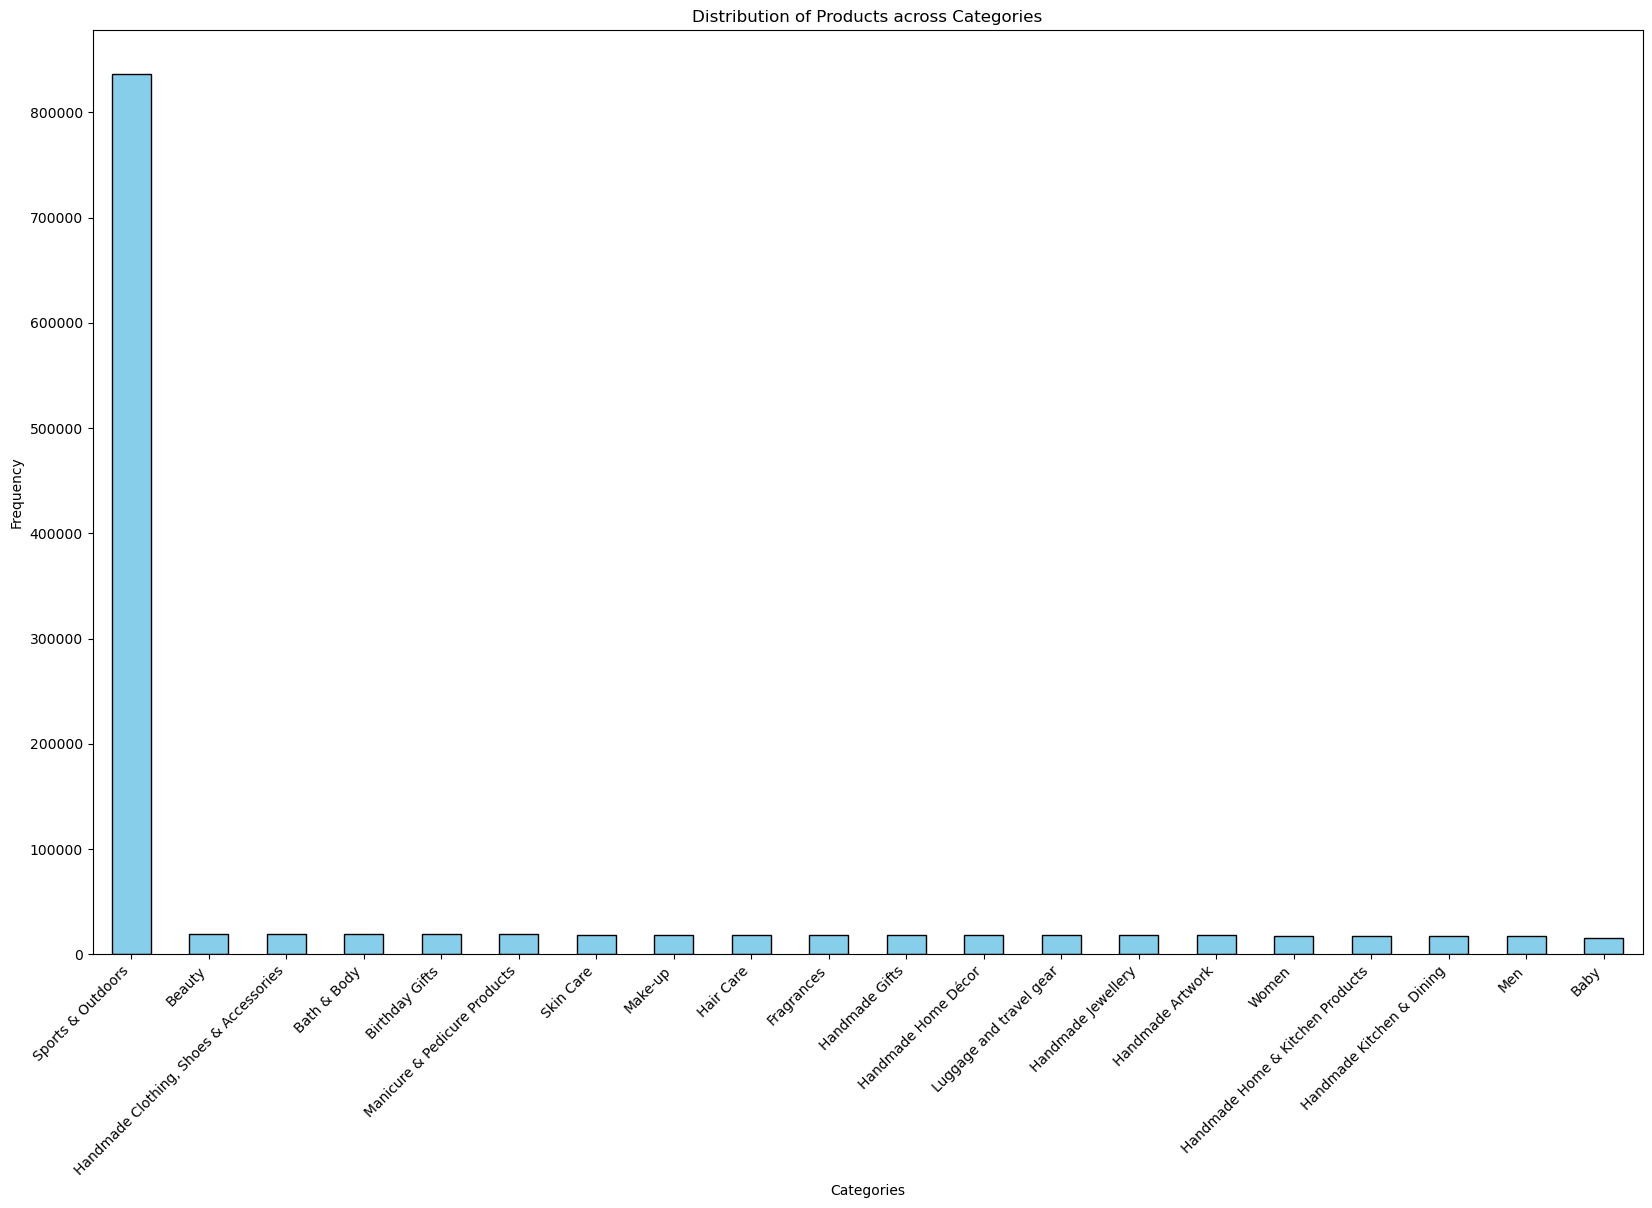

In [64]:
# Si ta crosstab s'appelle 'category_freq'
top_20_categories = freq_value_category.head(20)
# Si ta crosstab s'appelle 'category_freq'
top_20_categories.plot(kind='bar', figsize=(20, 12), color='skyblue', edgecolor='black')

plt.title('Distribution of Products across Categories')
plt.xlabel('Categories')
plt.ylabel('Frequency')
plt.xticks(rotation=45, ha='right') # Pour que les noms ne se chevauchent pas
plt.show()

Because of the outlier very extrem we can't see the value of the main catégories. That's why we are going to mask the sport ans outdoors to make the understanding easier.

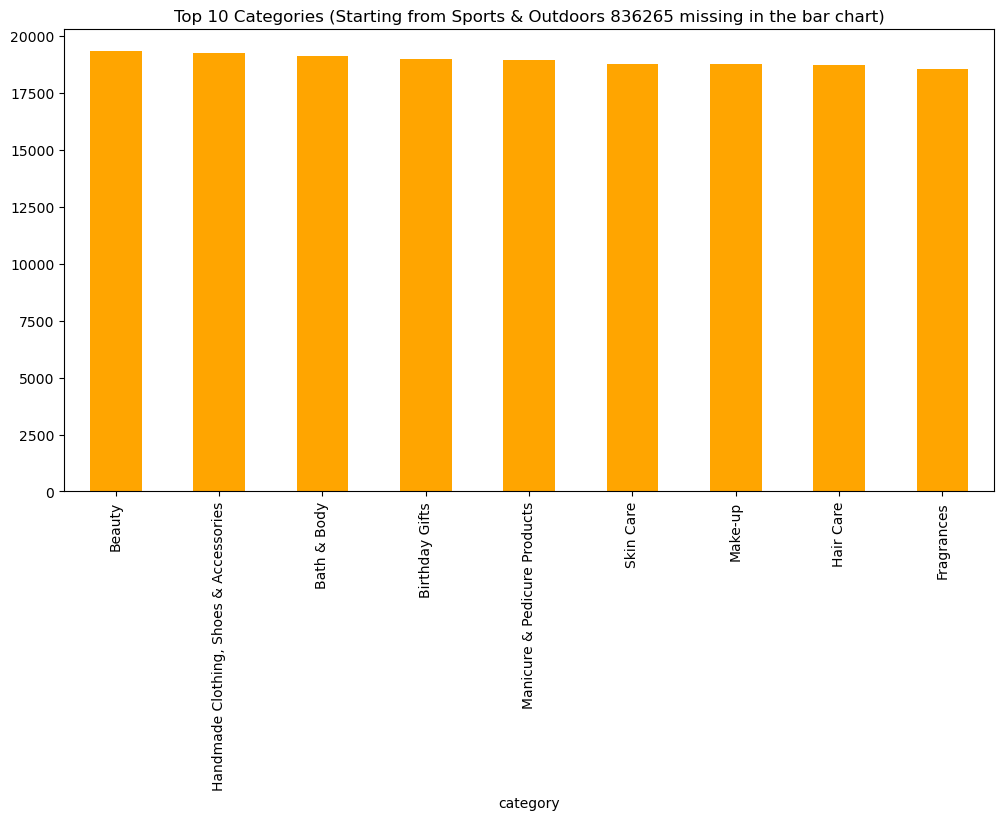

In [68]:
# Le [1:11] signifie : ignore l'élément 0 (le plus gros), prends de 1 à 10.
top_categories_no_outlier = freq_value_category.iloc[1:10]

top_categories_no_outlier.plot(kind='bar', figsize=(12, 6), color='orange')
plt.title('Top 10 Categories (Starting from Sports & Outdoors 836265 missing in the bar chart)')
plt.show()

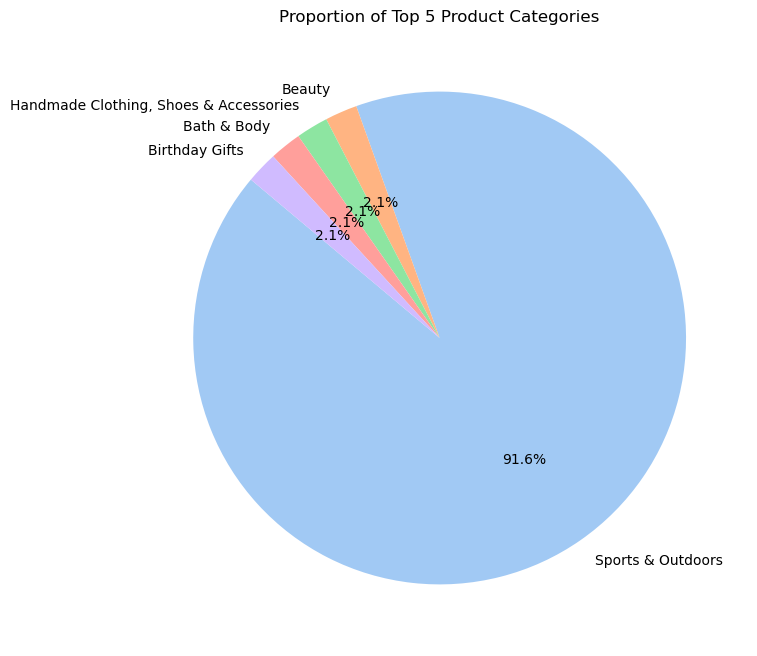

In [103]:
# Enhanced Pie Chart for Top 5 Categories
top_5_categories = freq_value_category.head(5)

plt.figure(figsize=(8, 8))
plt.pie(top_5_categories, labels=top_5_categories.index, autopct='%1.1f%%', startangle=140, colors=sns.color_palette('pastel'))
plt.title('Proportion of Top 5 Product Categories')
plt.show()

## Visualizations:
Display the distribution of products across different categories using a bar chart. If you face problems understanding the chart, do it for a subset of top categories.
For a subset of top categories, visualize their proportions using a pie chart. Does any category dominate the listings?

**to respond to this exercices, we will exclud the main category to make  the bar chart readable**

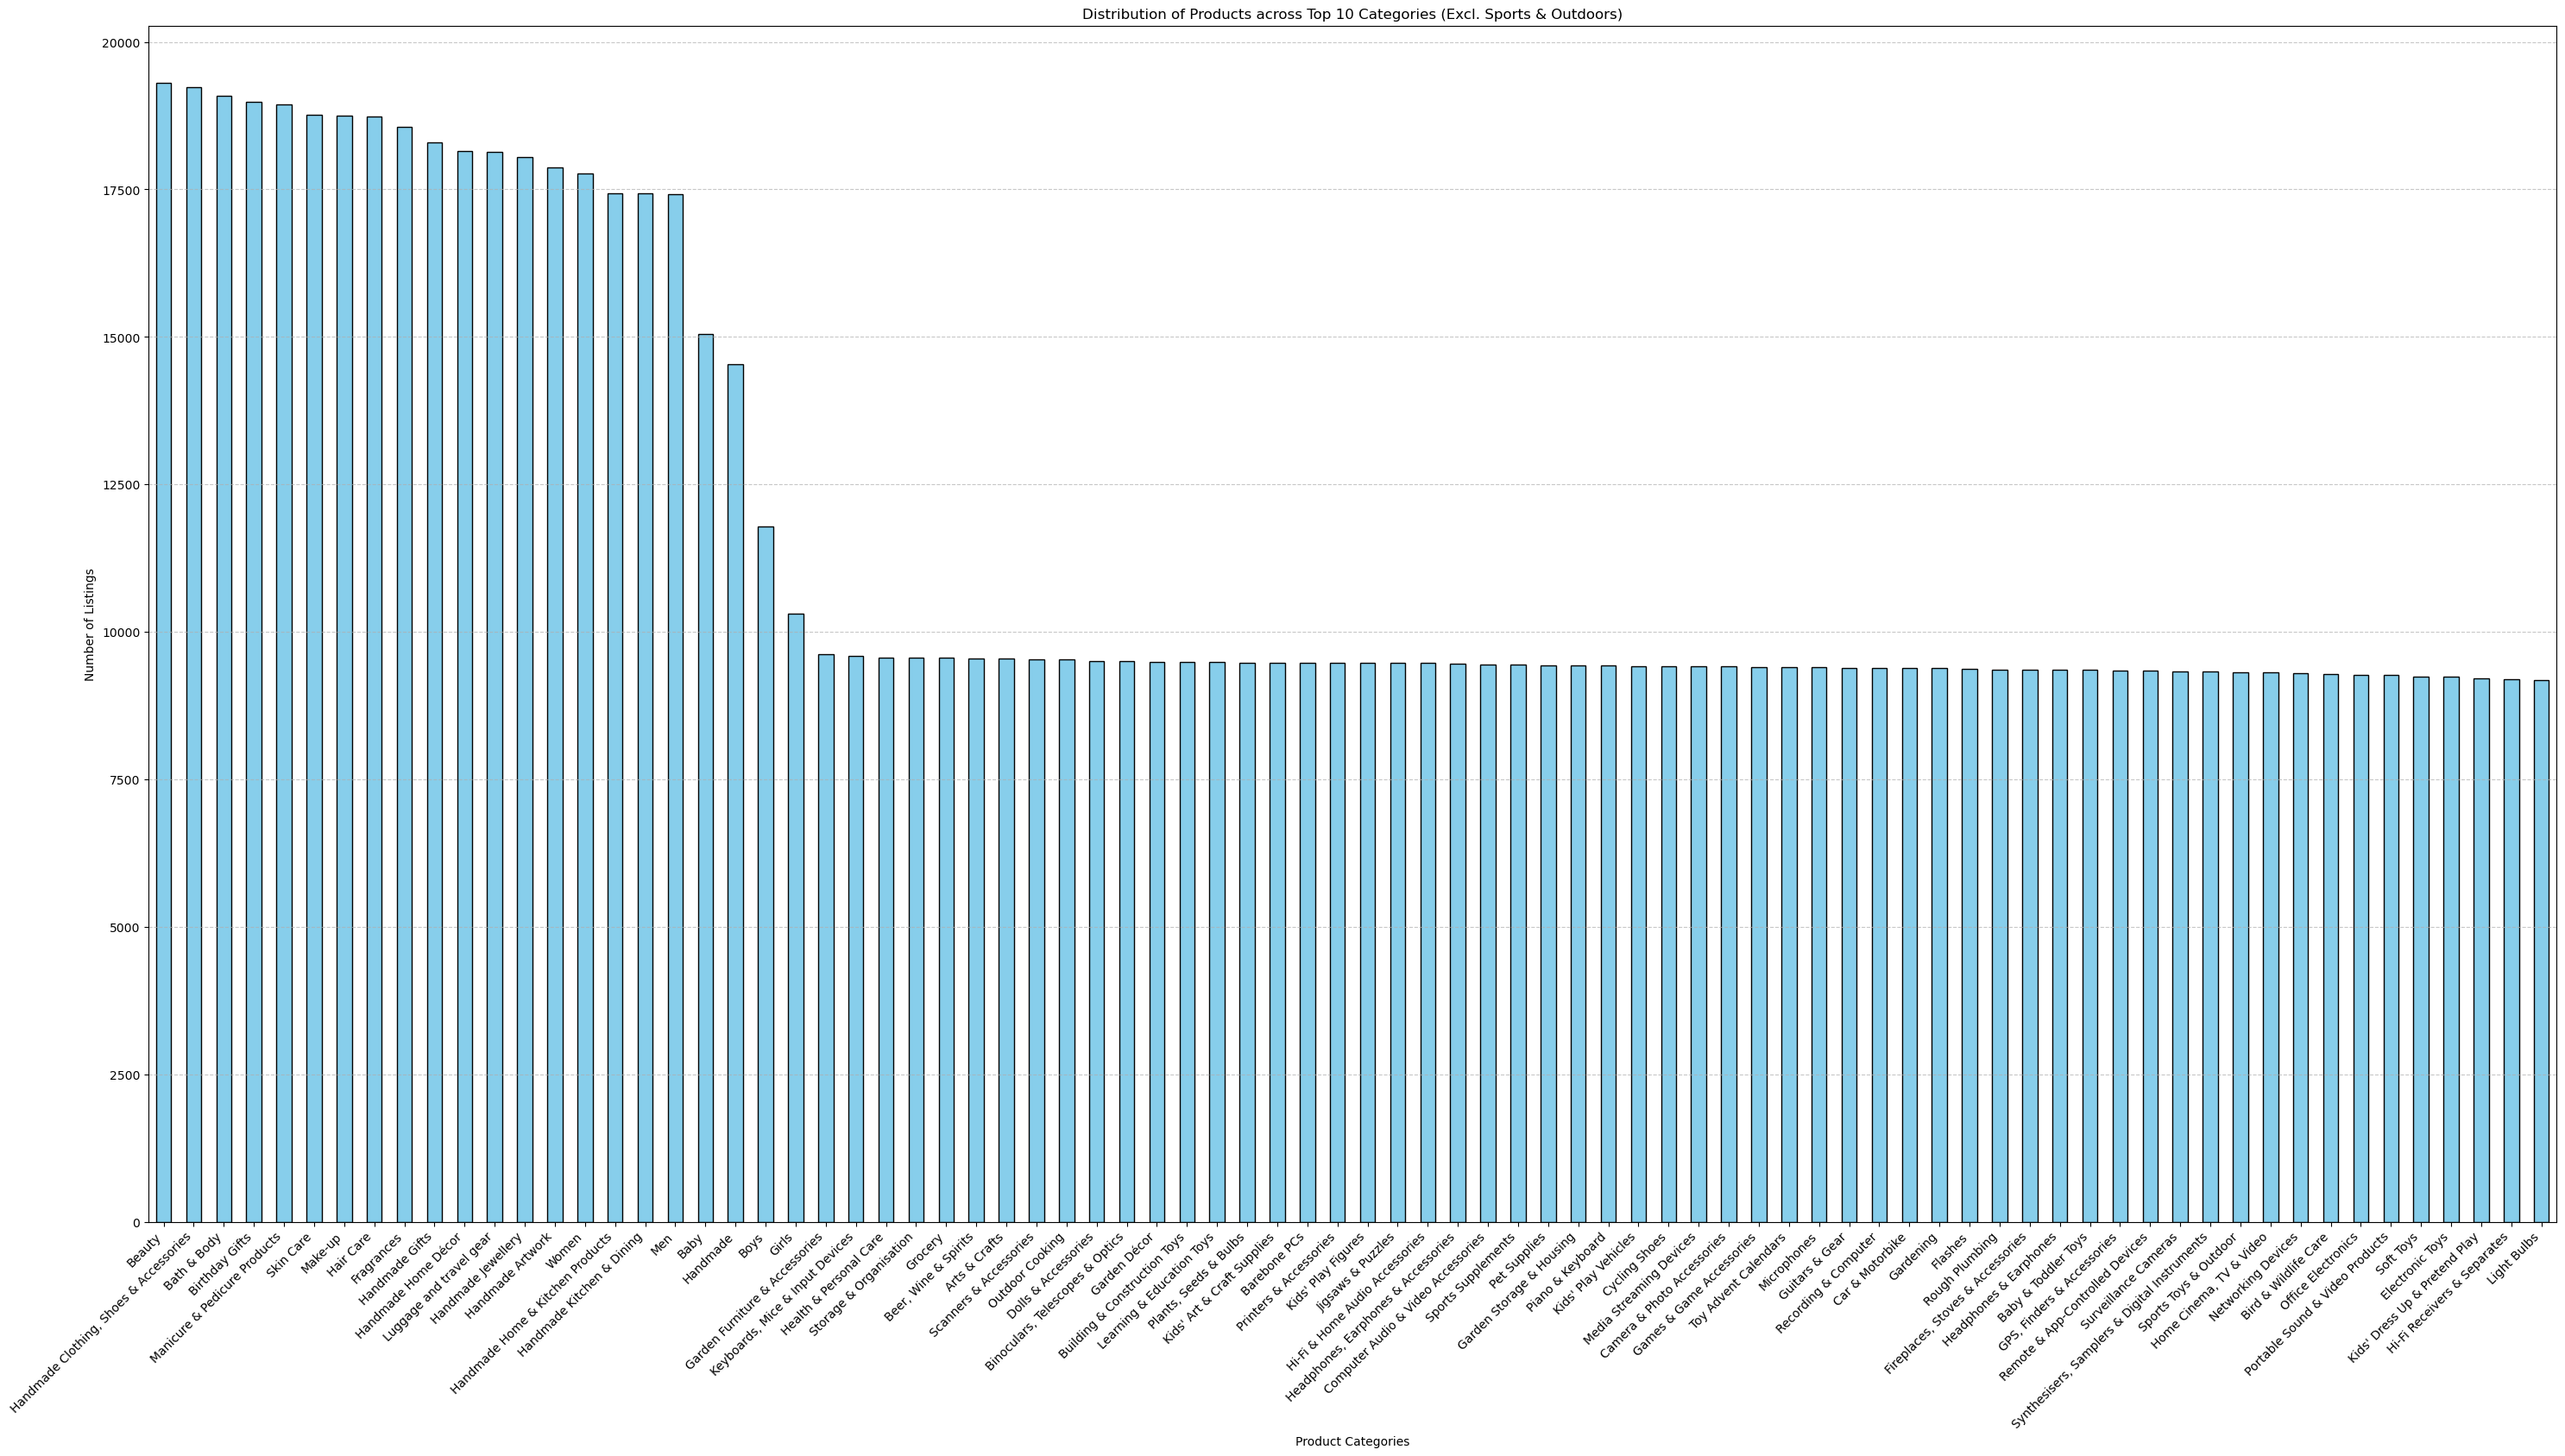

In [ ]:
import matplotlib.pyplot as plt

subset_categories = freq_value_category.drop('Sports & Outdoors').head(80)

# Création du Bar Chart
plt.figure(figsize=(36, 18))
subset_categories.plot(kind='bar', color='skyblue', edgecolor='black')

plt.title('Distribution of Products across Top 10 Categories (Excl. Sports & Outdoors)')
plt.xlabel('Product Categories')
plt.ylabel('Number of Listings')
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

## Business Question: How are products priced on Amazon UK, and are there specific price points or ranges that are more common?

### Measures of Centrality:
- Calculate the mean, median, and mode for the price of products.
- What's the average price point of products listed? How does this compare with the most common price point (mode)?

### Measures of Dispersion:
- Determine the variance, standard deviation, range, and interquartile range for product price.
- How varied are the product prices? Are there any indicators of a significant spread in prices?

### Visualizations:
- Is there a specific price range where most products fall? Plot a histogram to visualize the distribution of product prices. If its hard to read these diagrams, think why this is, and explain how it could be solved..
- Are there products that are priced significantly higher than the rest? Use a box plot to showcase the spread and potential outliers in product pricing

In [84]:
# The central tendency measures for the 'price' column are as follows:

print(f"most common price(s) of price: {df_cleaned['price'].mode().values}")
print(f"median of price: {df_cleaned['price'].median():.2f}")
print(f"mean of price: {df_cleaned['price'].mean():.2f}")


most common price(s) of price: [9.99]
median of price: 19.09
mean of price: 89.24


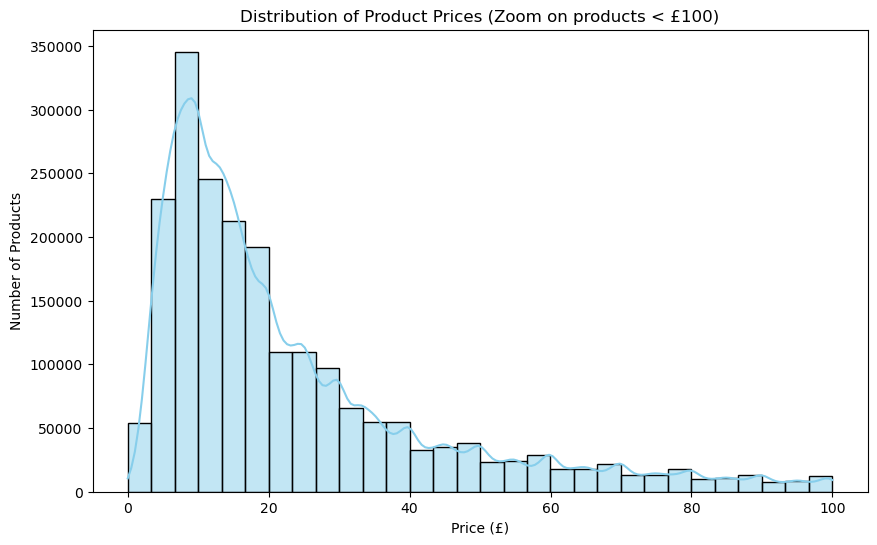

In [104]:
# Visualisation de la distribution des prix
plt.figure(figsize=(10, 6))
# On filtre < 100 pour avoir une visualisation lisible (Zoom sur la masse)
sns.histplot(df_cleaned[df_cleaned['price'] < 100]['price'], bins=30, kde=True, color='skyblue')

plt.title('Distribution of Product Prices (Zoom on products < £100)')
plt.xlabel('Price (£)')
plt.ylabel('Number of Products')
plt.show()

In [82]:
# What's the average price point of products listed? How does this compare with the most common price point (mode)?
#We are face a skewed distribution where the mean price is higher than the median and mode, indicating that a few high-priced items are pulling the average up.
if df_cleaned["price"].mean() > df_cleaned["price"].median() and df_cleaned["price"].mean() > df_cleaned["price"].mode().values:
    print ("The distribution is right-skewed.")
else:
    print ("The distribution is not right-skewed.")

The distribution is right-skewed.


In [83]:
# Mesures de dispersion
variance_price = df_cleaned['price'].var()
std_price = df_cleaned['price'].std()
price_range = df_cleaned['price'].max() - df_cleaned['price'].min()

print(f"Variance: {variance_price:.2f}")
print(f"Standard Deviation: {std_price:.2f}")
print(f"Price Range: {price_range:.2f} £")

if std_price > (0.5 * df_cleaned['price'].mean()):
    print("The prices are highly dispersed.")

Variance: 119445.49
Standard Deviation: 345.61
Price Range: 100000.00 £
The prices are highly dispersed.


## Visualizations:

- Is there a specific price range where most products fall? Plot a histogram to visualize the distribution of product prices. If its hard to read these diagrams, think why this is, and explain how it could be solved..
- Are there products that are priced significantly higher than the rest? Use a box plot to showcase the spread and potential outliers in product pricing.

See the barplot above. The oulier is the sport and outdoors categories

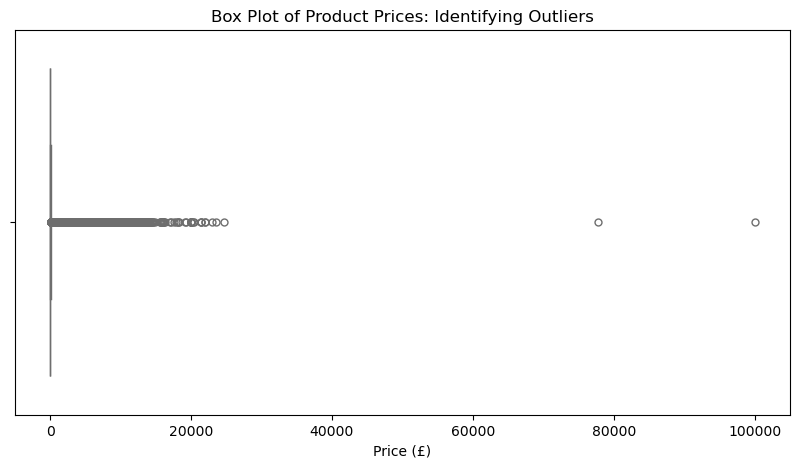

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# On crée la figure
plt.figure(figsize=(10, 5))

# Création du boxplot pour la colonne 'price'
# On peut le mettre à l'horizontale (x=...) ou à la verticale (y=...)
sns.boxplot(x=df_cleaned['price'], color='lightcoral', fliersize=5)

# Ajout des détails pour le rapport
plt.title('Box Plot of Product Prices: Identifying Outliers')
plt.xlabel('Price (£)')

plt.show()

In [87]:
# Calculate Quartiles and IQR (Interquartile Range)
Q1 = df_cleaned['price'].quantile(0.25)
Q3 = df_cleaned['price'].quantile(0.75)
IQR = Q3 - Q1

# 2. Define the Outlier Thresholds
# Standard statistical rule: Q3 + 1.5 * IQR
upper_bound = Q3 + (1.5 * IQR)

# 3. Filter the Outliers
# We focus on the upper bound as prices cannot be negativ
outliers_df_cleaned = df_cleaned[df_cleaned['price'] > upper_bound]

# 4. Sort and Display the results (Product Name and Price)
outliers_sorted = outliers_df_cleaned[['title', 'price']].sort_values(by='price', ascending=False)

print(f"--- Pricing Outlier Analysis ---")
print(f"Price threshold for outliers: {upper_bound:.2f} £")
print(f"Number of outliers detected: {len(outliers_sorted)}")
print("-" * 40)
print("Top 10 Most Expensive Outliers:")
print(outliers_sorted.head(10))

--- Pricing Outlier Analysis ---
Price threshold for outliers: 99.99 £
Number of outliers detected: 327688
----------------------------------------
Top 10 Most Expensive Outliers:
                                                     title      price
2008013                              HB FBA Test Treadmill  100000.00
1987238  Générique L.A 350° - I5 11400F - RTX 3050 8G -...   77752.00
1905315  Abaodam decor christmas ornaments Desk Ornamen...   24674.59
1408966                  BM4445-FI1-01200R10-03-E03 Driver   23482.73
319555   HEDUSA Halloween 3D Holographic Fan 3D Hologra...   22933.42
1490286  YXHUI Kids Girls Figure Skating Dress Long Sle...   21999.00
1490285  YXHUI Kids Girls Figure Skating Dress Long Sle...   21999.00
1907271  Outdoor Furniture Wood Porch Swing Black Brown...   21464.82
1907273  Outdoor Furniture Wood Porch Swing Black Brown...   21464.82
1907272  Outdoor Furniture Wood Porch Swing Black Brown...   21464.82


## Business Question: How do customers rate products on Amazon UK, and are there any patterns or tendencies in the ratings?

### Measures of Centrality:
Calculate the mean, median, and mode for the rating of products.
How do customers generally rate products? Is there a common trend?

### Measures of Dispersion:
Determine the variance, standard deviation, and interquartile range for product rating.
Are the ratings consistent, or is there a wide variation in customer feedback?

### Shape of the Distribution:
Calculate the skewness and kurtosis for the rating column.
Are the ratings normally distributed, or do they lean towards higher or lower values?
### Visualizations:
Plot a histogram to visualize the distribution of product ratings. Is there a specific rating that is more common?

In [89]:
df_cleaned

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers
...,...,...,...,...,...,...,...,...,...
2443646,2828589,B0CHSD7P2Q,"Motorbike Armour, Motorbike Clothing, Cycling ...",0.0,0,22.34,False,0,Motorbike Clothing
2443647,2828590,B0B7B8FNBQ,PROFIRST Waterproof Motorcycle 2 Piece Ladies ...,0.0,0,97.99,False,0,Motorbike Clothing
2443648,2828591,B0BD5FL5FB,Men’s Motorcycle Motorbike Biker Trousers Kevl...,0.0,0,52.99,False,0,Motorbike Clothing
2443649,2828592,B008OYLL4I,Texpeed Mens Motorcycle Motorbike Biker Trouse...,4.3,404,79.99,False,0,Motorbike Clothing


In [ ]:
# 1. Measures of Centrality
rating_mean = df_cleaned['stars'].mean()
rating_median = df_cleaned['stars'].median()
rating_mode = df_cleaned['stars'].mode()[0]

# 2. Measures of Dispersion
rating_variance = df_cleaned['stars'].var()
rating_std = df_cleaned['stars'].std()
rating_iqr = df_cleaned['stars'].quantile(0.75) - df_cleaned['stars'].quantile(0.25)

# 3. Shape of the Distribution
rating_skew = df_cleaned['stars'].skew()
rating_kurt = df_cleaned['stars'].kurt()

print(f"--- Customer Ratings Analysis ---")
print(f"Mean: {rating_mean:.2f} | Median: {rating_median:.2f} | Mode: {rating_mode:.2f}")
print(f"Std Dev: {rating_std:.2f} | IQR: {rating_iqr:.2f}")


--- Customer Ratings Analysis ---
Mean: 2.15 | Median: 0.00 | Mode: 0.00
Std Dev: 2.19 | IQR: 4.40
Skewness: 0.08 | Kurtosis: -1.93


In [90]:
#because of the absence of rate, the statistical analysis is not relevant. That's why we are going to remove the "0" stars
# 1. Create a subset excluding products with 0 stars
rated_products = df_cleaned[df_cleaned['stars'] > 0]

# 2. Re-calculate Measures of Centrality on the clean subset
rating_mean = rated_products['stars'].mean()
rating_median = rated_products['stars'].median()
rating_mode = rated_products['stars'].mode()[0]

# 3. Re-calculate Measures of Dispersion
rating_std = rated_products['stars'].std()
rating_var = rated_products['stars'].var()
rating_iqr = rated_products['stars'].quantile(0.75) - rated_products['stars'].quantile(0.25)

# 4. Re-calculate Shape
rating_skew = rated_products['stars'].skew()
rating_kurt = rated_products['stars'].kurt()

print(f"--- Clean Customer Ratings Analysis (Excluding 0s) ---")
print(f"Mean: {rating_mean:.2f} | Median: {rating_median:.2f} | Mode: {rating_mode:.2f}")
print(f"Std Dev: {rating_std:.2f} | IQR: {rating_iqr:.2f}")

--- Clean Customer Ratings Analysis (Excluding 0s) ---
Mean: 4.32 | Median: 4.40 | Mode: 4.50
Std Dev: 0.56 | IQR: 0.50


In this case we can observe that the dispersion are close the the median and we can notice that in average, custumers are statisfied with 4.32 at the mean with a median at 4.4 with the most rate at 4.5.

In [96]:
print(f"Skewness: {rating_skew:.2f} | Kurtosis: {rating_kurt:.2f}")

if rating_skew < -1:
    skew_comment = "Strong Negative Skew: Ratings are heavily concentrated on the high end (4-5 stars)."
elif rating_skew > 1:
    skew_comment = "Strong Positive Skew: Ratings are concentrated on the low end (1-2 stars)."
else:
    skew_comment = "Relatively Symmetric: Ratings are more evenly distributed."

print(f"Skewness: {rating_skew:.2f} -> {skew_comment}")

Skewness: -2.38 | Kurtosis: 9.78
Skewness: -2.38 -> Strong Negative Skew: Ratings are heavily concentrated on the high end (4-5 stars).


In [97]:
# En Python (Pandas), 0 est la valeur de référence pour une distribution normale
if rating_kurt > 1:
    kurt_comment = "Leptokurtic: Very high concentration around the average. High consensus among customers."
elif rating_kurt < -1:
    kurt_comment = "Platykurtic: Flat distribution. Very diverse and spread-out customer opinions."
else:
    kurt_comment = "Mesokurtic: Normal-like distribution."

print(f"Kurtosis: {rating_kurt:.2f} -> {kurt_comment}")

Kurtosis: 9.78 -> Leptokurtic: Very high concentration around the average. High consensus among customers.


Deep Dive into Ratings Skewness adand Kurtosis

The calculated Skewness is -2.38, which represents an extreme negative asymmetry. Therefore, Kurtosis at 9.78 seems more a consensus than opinion

Interpretation: This indicates that the vast majority of product ratings are concentrated at the highest possible value (5.0). The "average" customer experience on Amazon UK is statistically biased toward excellence.

Critical Perspective: Such an extreme value suggests a "Winner-Takes-All" marketplace. However, from an auditing standpoint, a skewness of this magnitude (-2.38) in addition with an hight kurtosis must warrant caution. It could either reflect Amazon's efficiency in surfacing top-rated products or point towards potential "rating inflation" (incentivized reviews) that artificially skews the perception of quality.

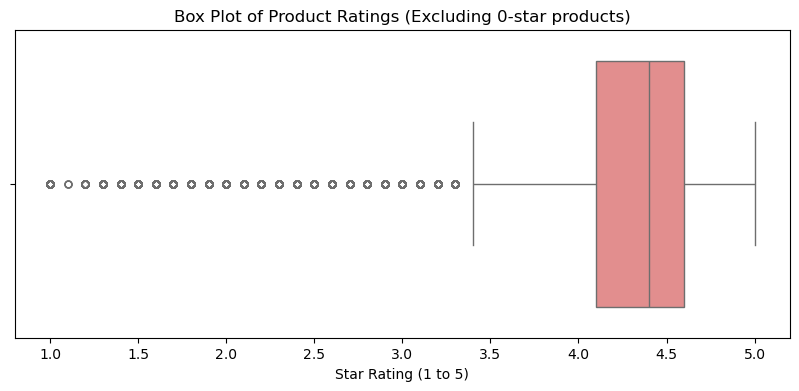

In [101]:
import matplotlib.pyplot as plt
import seaborn as sns # <--- Ne pas oublier l'import de Seaborn

# Filtrer pour ne garder que les produits avec au moins une note
# Cela permet de voir la vraie concentration des avis clients
df_stars_only = df_cleaned[df_cleaned['stars'] > 0]

plt.figure(figsize=(10, 4))

# Création du boxplot
sns.boxplot(x=df_stars_only['stars'], color='lightcoral', fliersize=5)

# Ajout des détails
plt.title('Box Plot of Product Ratings (Excluding 0-star products)')
plt.xlabel('Star Rating (1 to 5)')

plt.show()

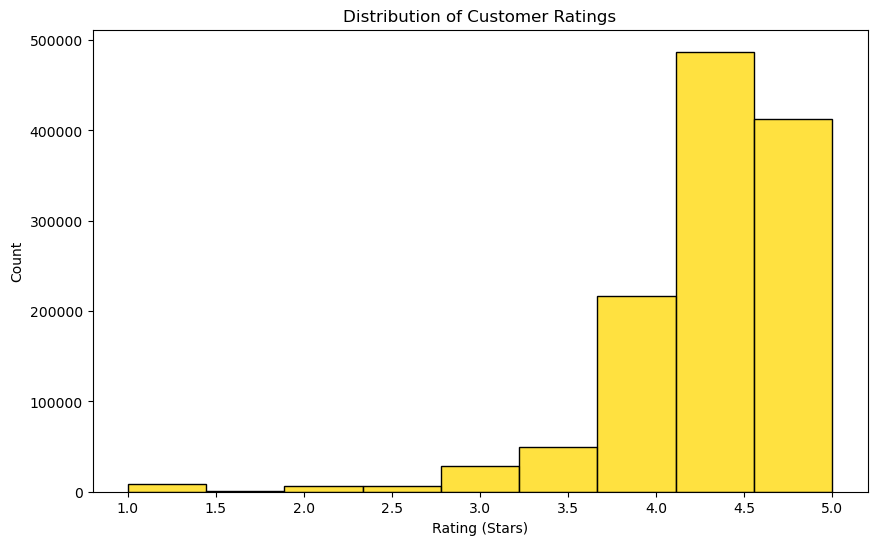

In [105]:
# Histogramme de la distribution des notes clients
plt.figure(figsize=(10, 6))
# On utilise les données filtrées (sans les 0) que nous avons créées ensemble
sns.histplot(df_stars_only['stars'], bins=9, kde=False, color='gold', edgecolor='black')

plt.title('Distribution of Customer Ratings')
plt.xlabel('Rating (Stars)')
plt.ylabel('Count')
plt.xticks(np.arange(1, 5.5, 0.5)) # Pour voir les demi-étoiles
plt.show()

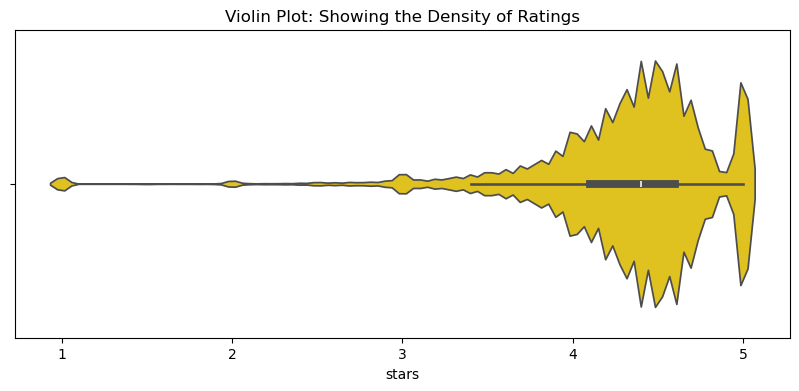

In [102]:
plt.figure(figsize=(10, 4))
sns.violinplot(x=df_stars_only['stars'], color='gold')
plt.title('Violin Plot: Showing the Density of Ratings')
plt.show()

The violin plot is more relevant to display the concentration of very good rates anormaly hight